In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load dataset
data = load_breast_cancer()

# Separate features and target
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="Target")

print("Dataset loaded successfully!")

print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFirst 5 rows:")
display(X.head())

print("\nTarget classes:")
print(data.target_names)

print("\nClass distribution:")
print(y.value_counts())

Dataset loaded successfully!
Number of rows: 569
Number of features: 30

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target classes:
['malignant' 'benign']

Class distribution:
Target
1    357
0    212
Name: count, dtype: int64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [4]:
base_models = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", probability=True, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Naive Bayes": GaussianNB()
}

print("Base classifiers created successfully!")

Base classifiers created successfully!


In [5]:
stacking_model = StackingClassifier(
    estimators=[
        ("svm", make_pipeline(
            StandardScaler(),
            SVC(probability=True, random_state=42)
        )),

        ("dt", DecisionTreeClassifier(
            random_state=42
        )),

        ("knn", make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5)
        )),

        ("nb", GaussianNB())
    ],

    final_estimator=LogisticRegression(
        max_iter=1000
    ),

    cv=5
)

print("Stacking Ensemble created successfully!")

# Train the model
stacking_model.fit(X_train, y_train)

# Make predictions
stacking_pred = stacking_model.predict(X_test)

print("Stacking predictions:")
print(stacking_pred[:10])

Stacking Ensemble created successfully!
Stacking predictions:
[0 1 0 1 0 1 1 0 0 0]


In [6]:
adaboost_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

print("AdaBoost Ensemble created successfully!")

# Train the model
adaboost_model.fit(X_train, y_train)

# Make predictions
adaboost_pred = adaboost_model.predict(X_test)

print("AdaBoost predictions:")
print(adaboost_pred[:10])

AdaBoost Ensemble created successfully!
AdaBoost predictions:
[0 1 0 0 0 1 1 0 0 0]


In [7]:
voting_model = VotingClassifier(
    estimators=[
        ("svm", make_pipeline(
            StandardScaler(),
            SVC(probability=True, random_state=42)
        )),

        ("dt", DecisionTreeClassifier(
            random_state=42
        )),

        ("knn", make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5)
        )),

        ("nb", GaussianNB())
    ],

    voting="hard"
)

print("Voting Ensemble created successfully!")

# Train the model
voting_model.fit(X_train, y_train)

# Make predictions
voting_pred = voting_model.predict(X_test)

print("Voting predictions:")
print(voting_pred[:10])

Voting Ensemble created successfully!
Voting predictions:
[0 1 0 1 0 1 1 0 0 0]


In [8]:
voting_model = VotingClassifier(
    estimators=[
        ("svm", make_pipeline(
            StandardScaler(),
            SVC(probability=True, random_state=42)
        )),

        ("dt", DecisionTreeClassifier(
            random_state=42
        )),

        ("knn", make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5)
        )),

        ("nb", GaussianNB())
    ],

    voting="hard"
)

print("Voting Ensemble created successfully!")

# Train the model
voting_model.fit(X_train, y_train)

# Make predictions
voting_pred = voting_model.predict(X_test)

print("Voting predictions:")
print(voting_pred[:10])

Voting Ensemble created successfully!
Voting predictions:
[0 1 0 1 0 1 1 0 0 0]


In [9]:
# Combine all models
all_models = {
    **base_models,
    "Stacking": stacking_model,
    "AdaBoost": adaboost_model,
    "Voting": voting_model
}

results = []
trained_models = {}

for name, model in all_models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict output
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    # Calculate log loss wherever probabilities are available
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)
        loss = log_loss(y_test, y_prob, labels=[0, 1])
    else:
        loss = np.nan

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Log Loss": loss
    })

    trained_models[name] = model

# Create comparison table
results_df = pd.DataFrame(results)

print("COMPARISON OF ALL MODELS")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Log Loss": lambda x: "N/A" if pd.isna(x) else f"{x:.4f}"
    })
)

COMPARISON OF ALL MODELS


,Algorithm,Accuracy,Precision,Recall,F1-Score,Log Loss
0,SVM,0.9825,0.9825,0.9825,0.9825,0.0860
1,Decision Tree,0.9123,0.9161,0.9123,0.9130,3.1617
2,KNN,0.9561,0.9561,0.9561,0.9560,0.4073
3,Naive Bayes,0.9386,0.9384,0.9386,0.9384,0.3713
4,Stacking,0.9737,0.9737,0.9737,0.9736,0.0976
5,AdaBoost,0.9561,0.9569,0.9561,0.9558,0.3829
6,Voting,0.9737,0.9737,0.9737,0.9736,N/A


In [10]:
for name, model in trained_models.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=data.target_names,
            zero_division=0
        )
    )


SVM
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Decision Tree
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


KNN
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96      

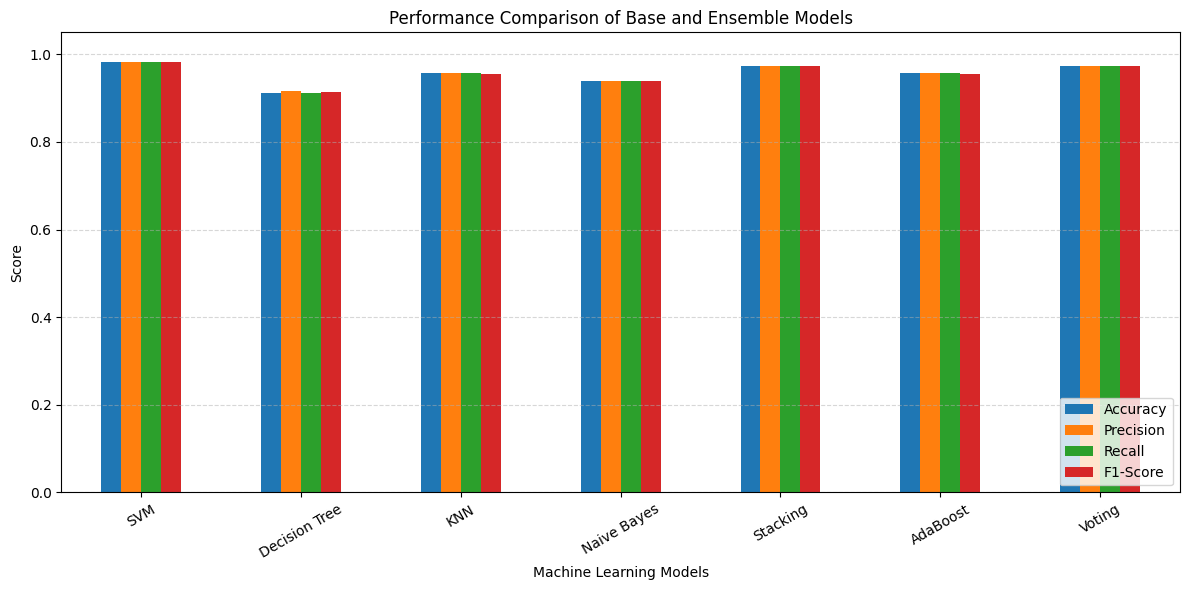

In [11]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

results_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("Performance Comparison of Base and Ensemble Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

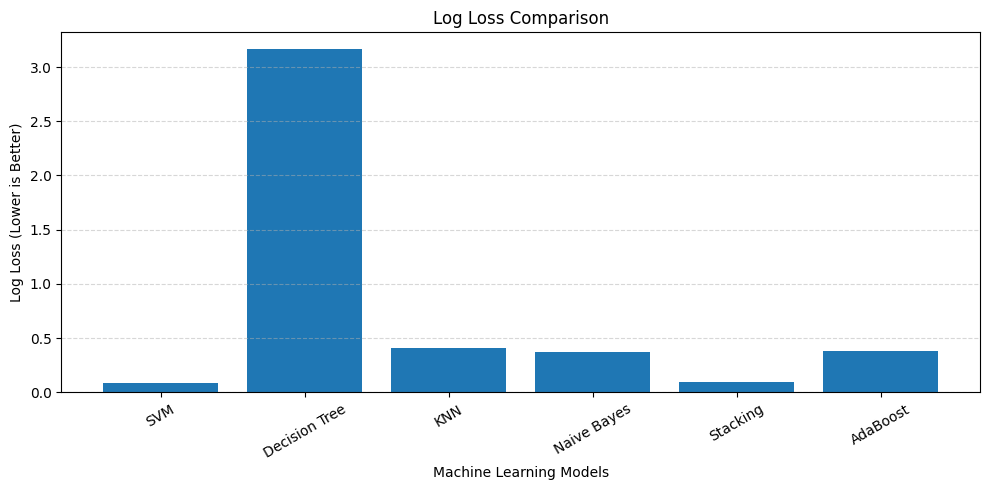

In [12]:
loss_df = results_df.dropna(subset=["Log Loss"])

plt.figure(figsize=(10, 5))

plt.bar(
    loss_df["Algorithm"],
    loss_df["Log Loss"]
)

plt.title("Log Loss Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Log Loss (Lower is Better)")
plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

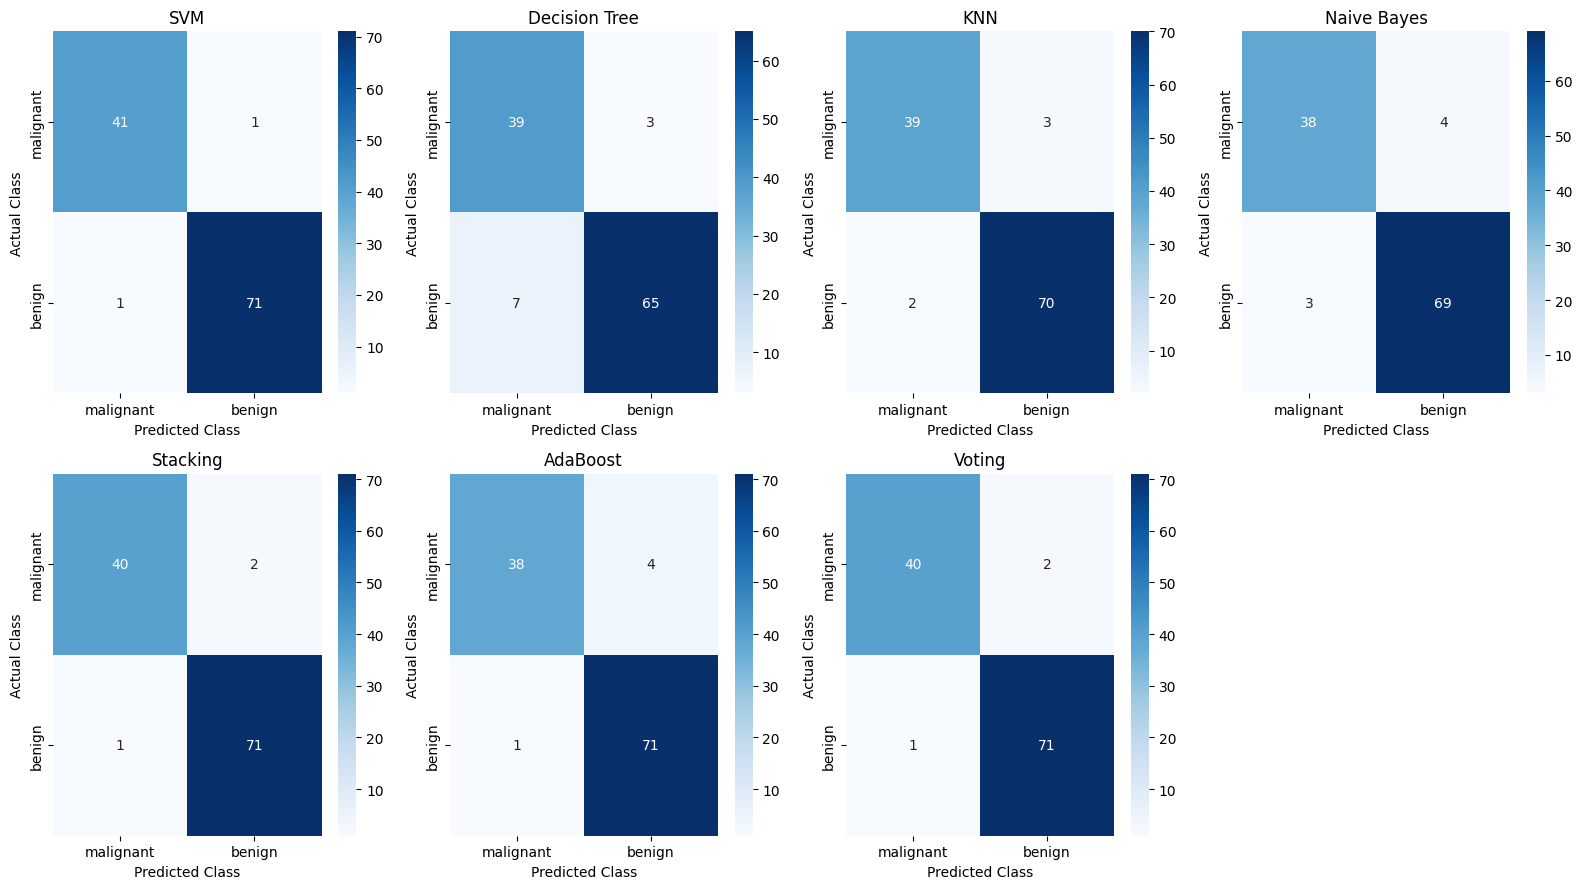

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for ax, (name, model) in zip(axes.ravel(), trained_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=data.target_names,
        yticklabels=data.target_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

# Hide the unused eighth plot
axes.ravel()[-1].axis("off")

plt.tight_layout()
plt.show()

In [14]:
print("BEST MODEL ACCORDING TO EACH METRIC\n")

for metric in ["Accuracy", "Precision", "Recall", "F1-Score"]:

    best_row = results_df.loc[
        results_df[metric].idxmax()
    ]

    print(
        metric, ":",
        best_row["Algorithm"],
        "(" + str(round(best_row[metric], 4)) + ")"
    )

# Lowest log loss
loss_df = results_df.dropna(subset=["Log Loss"])

best_loss = loss_df.loc[
    loss_df["Log Loss"].idxmin()
]

print(
    "\nLowest Log Loss:",
    best_loss["Algorithm"],
    "(" + str(round(best_loss["Log Loss"], 4)) + ")"
)

BEST MODEL ACCORDING TO EACH METRIC

Accuracy : SVM (0.9825)
Precision : SVM (0.9825)
Recall : SVM (0.9825)
F1-Score : SVM (0.9825)

Lowest Log Loss: SVM (0.086)


In [15]:
# Take one sample from the test dataset
new_sample = X_test.iloc[[0]]

print("New Input Data:")
display(new_sample)

print("\nPredictions from all models:")

for name, model in trained_models.items():

    prediction = model.predict(new_sample)[0]

    print(
        name, ":",
        data.target_names[prediction]
    )

New Input Data:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
256,19.55,28.77,133.6,1207.0,0.0926,0.2063,0.1784,0.1144,0.1893,0.06232,...,25.05,36.27,178.6,1926.0,0.1281,0.5329,0.4251,0.1941,0.2818,0.1005



Predictions from all models:
SVM : malignant
Decision Tree : malignant
KNN : malignant
Naive Bayes : malignant
Stacking : malignant
AdaBoost : malignant
Voting : malignant


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:

test_cases = [
    {
        "Test Case": "TC1 – Base Models Evaluation",
        "Input": "Test dataset",
        "Expected Output": "Calculate performance metrics",
        "Actual Output": "; ".join(
            [
                f"{row['Algorithm']}: Accuracy {row['Accuracy']:.4f}, "
                f"F1-Score {row['F1-Score']:.4f}"
                for _, row in results_df.iloc[:4].iterrows()
            ]
        ),
        "Status": "Successful"
    },
    {
        "Test Case": "TC2 – Stacking Evaluation",
        "Input": "Test dataset",
        "Expected Output": "Calculate performance metrics",
        "Actual Output": (
            f"Accuracy: {results_df.loc[results_df['Algorithm']=='Stacking', 'Accuracy'].iloc[0]:.4f}, "
            f"F1-Score: {results_df.loc[results_df['Algorithm']=='Stacking', 'F1-Score'].iloc[0]:.4f}"
        ),
        "Status": "Successful"
    },
    {
        "Test Case": "TC3 – AdaBoost Evaluation",
        "Input": "Test dataset",
        "Expected Output": "Calculate performance metrics",
        "Actual Output": (
            f"Accuracy: {results_df.loc[results_df['Algorithm']=='AdaBoost', 'Accuracy'].iloc[0]:.4f}, "
            f"F1-Score: {results_df.loc[results_df['Algorithm']=='AdaBoost', 'F1-Score'].iloc[0]:.4f}"
        ),
        "Status": "Successful"
    },
    {
        "Test Case": "TC4 – Voting Evaluation",
        "Input": "Test dataset",
        "Expected Output": "Calculate performance metrics",
        "Actual Output": (
            f"Accuracy: {results_df.loc[results_df['Algorithm']=='Voting', 'Accuracy'].iloc[0]:.4f}, "
            f"F1-Score: {results_df.loc[results_df['Algorithm']=='Voting', 'F1-Score'].iloc[0]:.4f}"
        ),
        "Status": "Successful"
    },
    {
        "Test Case": "TC5 – Model Comparison",
        "Input": "Results of all seven models",
        "Expected Output": "Identify best-performing model",
        "Actual Output": (
            f"Highest Accuracy: {results_df.loc[results_df['Accuracy'].idxmax(), 'Algorithm']}, "
            f"Highest F1-Score: {results_df.loc[results_df['F1-Score'].idxmax(), 'Algorithm']}"
        ),
        "Status": "Successful"
    }
]

test_df = pd.DataFrame(test_cases)
display(test_df)


,Test Case,Input,Expected Output,Actual Output,Status
0,TC1 – Base Models Evaluation,Test dataset,Calculate performance metrics,"SVM: Accuracy 0.9825, F1-Score 0.9825; Decisio...",Successful
1,TC2 – Stacking Evaluation,Test dataset,Calculate performance metrics,"Accuracy: 0.9737, F1-Score: 0.9736",Successful
2,TC3 – AdaBoost Evaluation,Test dataset,Calculate performance metrics,"Accuracy: 0.9561, F1-Score: 0.9558",Successful
3,TC4 – Voting Evaluation,Test dataset,Calculate performance metrics,"Accuracy: 0.9737, F1-Score: 0.9736",Successful
4,TC5 – Model Comparison,Results of all seven models,Identify best-performing model,"Highest Accuracy: SVM, Highest F1-Score: SVM",Successful
